# RF-DETR-Seg Nano


## 1. Environment and imports

In [1]:
%pip install -q "rfdetr[train]==1.12.1" "supervision[metrics]==0.31.3" "pillow<13"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv
import json
import shutil
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import torch

## 2. Dataset configuration

In [3]:
from PIL import Image

dst = Path("/kaggle/working/rfdetr_seg_nano_runs")
CHECKPOINT_DIR = dst
RUN_TRAINING = True
GPU_COUNT = 2

if RUN_TRAINING and torch.cuda.device_count() < GPU_COUNT:
    raise RuntimeError("Select the Kaggle dual T4 GPU accelerator for training.")
if not RUN_TRAINING:
    for weights in ("pretrained", "scratch"):
        checkpoint = CHECKPOINT_DIR / weights / "checkpoint_best_total.pth"
        if not checkpoint.is_file():
            raise FileNotFoundError(f"Set CHECKPOINT_DIR to the saved runs directory. Missing {checkpoint}")

source = Path("/kaggle/input/datasets/paibarrr/panoptic-indoor-segmentation-coco/")
root = Path("/kaggle/working/panoptic_coco")
for split in ("train", "valid", "test"):
    source_dir = source / split
    target_dir = root / split
    target_dir.mkdir(parents=True, exist_ok=True)
    annotation_file = source_dir / "_annotations.coco.json"
    annotations = json.loads(annotation_file.read_text())
    shutil.copy2(annotation_file, target_dir / annotation_file.name)
    for image_info in annotations["images"]:
        image_file = source_dir / image_info["file_name"]
        target_file = target_dir / image_file.name
        if target_file.exists():
            continue
        with Image.open(image_file) as image:
            if image.size == (image_info["height"], image_info["width"]) and image.width != image.height:
                image.transpose(Image.Transpose.ROTATE_270).save(target_file, quality=95)
            else:
                shutil.copy2(image_file, target_file)

train = root / "train"
valid = root / "valid"
test = root / "test"
DATASET_DIR = root
OUTPUT_DIR = dst
RESUME_PRETRAINED = None
RESUME_SCRATCH = None
TRAIN_SCRIPT = Path("/kaggle/working/train_rfdetr.py")
EPOCHS = 50
BATCH_SIZE_PER_GPU = 4
GRAD_ACCUM_STEPS = 2
LEARNING_RATE = 1e-4

print(f"Dataset: {DATASET_DIR}")
print(f"GPUs: {torch.cuda.device_count()}")
for gpu_index in range(torch.cuda.device_count()):
    print(f"GPU {gpu_index}: {torch.cuda.get_device_name(gpu_index)}")

Dataset: /kaggle/working/panoptic_coco
GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Dataset checks and output directories

In [4]:
for split, split_dir in (("train", train), ("valid", valid), ("test", test)):
    annotation_file = split_dir / "_annotations.coco.json"
    annotations = json.loads(annotation_file.read_text())
    print(f"{split}: {len(annotations['images'])} images, {len(annotations['annotations'])} annotations")

train_annotations = json.loads((train / "_annotations.coco.json").read_text())
print(f"Classes: {len(train_annotations['categories'])}")

train: 397 images, 4479 annotations
valid: 166 images, 2022 annotations
test: 359 images, 5344 annotations
Classes: 75


In [5]:
ARTIFACT_DIR = OUTPUT_DIR / "report_artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

class_distribution = []
dataset_summary = {"dataset_dir": str(DATASET_DIR), "splits": {}, "classes": train_annotations["categories"]}

for split, split_dir in (("train", train), ("valid", valid), ("test", test)):
    annotation_data = json.loads((split_dir / "_annotations.coco.json").read_text())
    category_names = {item["id"]: item["name"] for item in annotation_data["categories"]}
    instance_counts = {category_id: 0 for category_id in category_names}
    for annotation in annotation_data["annotations"]:
        instance_counts[annotation["category_id"]] += 1
    dataset_summary["splits"][split] = {
        "images": len(annotation_data["images"]),
        "annotations": len(annotation_data["annotations"]),
    }
    class_distribution.extend([
        {"split": split, "class_id": category_id, "class_name": category_names[category_id], "instances": count}
        for category_id, count in instance_counts.items()
    ])

(ARTIFACT_DIR / "dataset_summary.json").write_text(json.dumps(dataset_summary, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "class_names.json").write_text(
    json.dumps([item["name"] for item in train_annotations["categories"]], indent=2),
    encoding="utf-8",
)
with (ARTIFACT_DIR / "class_distribution.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=["split", "class_id", "class_name", "instances"])
    writer.writeheader()
    writer.writerows(class_distribution)



## 4. Model and training setup

In [6]:
%%writefile /kaggle/working/train_rfdetr.py
import argparse
import json
from datetime import timedelta
from pathlib import Path

from pytorch_lightning.strategies import DDPStrategy

from rfdetr import RFDETRSegNano
from rfdetr.config import SegmentationTrainConfig
from rfdetr.training import RFDETRDataModule, RFDETRModelModule, build_trainer

parser = argparse.ArgumentParser()
parser.add_argument("--dataset-dir", required=True)
parser.add_argument("--weights", choices=("pretrained", "scratch"), required=True)
parser.add_argument("--resume", default="")
parser.add_argument("--epochs", type=int, default=50)
args = parser.parse_args()

DATASET_DIR = Path(args.dataset_dir)
OUTPUT_DIR = Path("/kaggle/working/rfdetr_seg_nano_runs") / args.weights
categories = json.loads((DATASET_DIR / "train" / "_annotations.coco.json").read_text())["categories"]
class_names = [item["name"] for item in categories if item["name"] != "indoor-objects"]

if args.weights == "scratch":
    model_config = RFDETRSegNano(
        pretrain_weights=None,
        freeze_encoder=False,
        num_classes=len(class_names),
    ).model_config
else:
    model_config = RFDETRSegNano(
        freeze_encoder=False,
        num_classes=len(class_names),
    ).model_config

train_config = SegmentationTrainConfig(
    dataset_dir=str(DATASET_DIR),
    output_dir=str(OUTPUT_DIR),
    epochs=args.epochs,
    batch_size=4,
    grad_accum_steps=2,
    lr=1e-4,
    seed=42,
    strategy="ddp",
    progress_bar=None,
    tensorboard=False,
    log_per_class_metrics=False,
    class_names=class_names,
    run_test=False,
    resume=args.resume or None,
)

module = RFDETRModelModule(
    model_config,
    train_config,
    load_encoder_weights=args.weights == "pretrained",
)
datamodule = RFDETRDataModule(model_config, train_config)
trainer = build_trainer(
    train_config,
    model_config,
    strategy=DDPStrategy(find_unused_parameters=True, timeout=timedelta(minutes=5)),
    devices="auto",
    log_every_n_steps=25,
)
trainer.fit(module, datamodule, ckpt_path=train_config.resume)


Writing /kaggle/working/train_rfdetr.py


In [7]:
def run_training(weights, resume_checkpoint=None):
    run_dir = OUTPUT_DIR / weights
    run_dir.mkdir(parents=True, exist_ok=True)
    metrics_file = run_dir / "metrics.csv"
    console_log = run_dir / "training_console.log"
    if resume_checkpoint:
        previous_metrics = Path(resume_checkpoint).parent / "metrics.csv"
        if previous_metrics.exists() and not metrics_file.exists():
            shutil.copy2(previous_metrics, metrics_file)
    command = [
        sys.executable,
        "-u",
        "-m",
        "torch.distributed.run",
        "--standalone",
        "--nnodes=1",
        f"--nproc_per_node={GPU_COUNT}",
        str(TRAIN_SCRIPT),
        "--dataset-dir",
        str(DATASET_DIR),
        "--weights",
        weights,
        "--resume",
        str(resume_checkpoint or ""),
        "--epochs",
        str(EPOCHS),
    ]
    started_at = datetime.now(timezone.utc).isoformat()
    start_time = time.perf_counter()
    status = "failed"
    try:
        if weights == "pretrained":
            from rfdetr.assets.model_weights import download_pretrain_weights, get_model_cache_dir
            from rfdetr.config import RFDETRSegNanoConfig

            filename = RFDETRSegNanoConfig().pretrain_weights
            cache_dir = Path(get_model_cache_dir())
            cache_dir.mkdir(parents=True, exist_ok=True)
            download_pretrain_weights(str(cache_dir / filename))
        print(f"{weights}: training on {GPU_COUNT} GPUs. Full log: {console_log}", flush=True)
        with console_log.open("a" if resume_checkpoint else "w", encoding="utf-8") as log:
            with subprocess.Popen(command, stdout=log, stderr=subprocess.STDOUT) as process:
                while True:
                    try:
                        return_code = process.wait(timeout=30)
                        break
                    except subprocess.TimeoutExpired:
                        message = f"{weights}: {time.perf_counter() - start_time:.0f}s elapsed"
                        try:
                            with metrics_file.open(newline="", encoding="utf-8") as csv_file:
                                rows = list(csv.DictReader(csv_file))
                        except FileNotFoundError:
                            rows = []
                        for row in reversed(rows):
                            mask_map = row.get("val/ema_segm_mAP_50_95") or row.get("val/segm_mAP_50_95")
                            if mask_map and (row.get("epoch") or "").isdigit():
                                message += f", last validation epoch {int(row['epoch']) + 1}/{EPOCHS}, mask mAP {mask_map}"
                                break
                        print(message, flush=True)
        if return_code:
            from collections import deque

            with console_log.open(encoding="utf-8", errors="replace") as log:
                print("".join(deque(log, maxlen=35)), flush=True)
            raise RuntimeError(f"{weights} training exited with code {return_code}. Full log: {console_log}")
        status = "completed"
    finally:
        metadata = {
            "model": "RF-DETR-Seg Nano",
            "weights": weights,
            "status": status,
            "started_at_utc": started_at,
            "elapsed_wall_seconds": round(time.perf_counter() - start_time, 2),
            "dataset_dir": str(DATASET_DIR),
            "train_images": len(train_annotations["images"]),
            "classes": len(train_annotations["categories"]),
            "epochs": EPOCHS,
            "batch_size_per_gpu": BATCH_SIZE_PER_GPU,
            "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
            "learning_rate": LEARNING_RATE,
            "seed": 42,
            "strategy": "DDP",
            "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
            "training_log": str(metrics_file),
            "training_console_log": str(console_log),
            "resume_checkpoint": str(run_dir / "last.ckpt"),
            "resumed_from": str(resume_checkpoint or ""),
            "inference_checkpoint": str(run_dir / "checkpoint_best_total.pth"),
        }
        (run_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
        (ARTIFACT_DIR / f"rfdetr_{weights}_run_metadata.json").write_text(
            json.dumps(metadata, indent=2), encoding="utf-8"
        )


## 5. Training runs

In [8]:
if RUN_TRAINING:
    run_training("pretrained", RESUME_PRETRAINED)


[2026-11-21 06:45:59] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-seg-nano.pt


/root/.roboflow/models/rf-detr-seg-nano.pt:   0%|          | 0.00/128M [00:00<?, ?iB/s]

[2026-11-21 06:46:01] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-seg-nano.pt
pretrained: training on 2 GPUs. Full log: /kaggle/working/rfdetr_seg_nano_runs/pretrained/training_console.log
pretrained: 53s elapsed
pretrained: 83s elapsed, last validation epoch 1/50, mask mAP 0.011489282362163067
pretrained: 113s elapsed, last validation epoch 2/50, mask mAP 0.03389142453670502
pretrained: 143s elapsed, last validation epoch 3/50, mask mAP 0.06278139352798462
pretrained: 173s elapsed, last validation epoch 4/50, mask mAP 0.08304353058338165
pretrained: 203s elapsed, last validation epoch 5/50, mask mAP 0.09639613330364227
pretrained: 233s elapsed, last validation epoch 6/50, mask mAP 0.1160605400800705
pretrained: 263s elapsed, last validation epoch 7/50, mask mAP 0.13223184645175934
pretrained: 293s elapsed, last validation epoch 8/50, mask mAP 0.14511723816394806
pretrained: 323s elapsed, last validation epoch 9/50, mask mAP 0.15641483664512634
pretrai

In [9]:
if RUN_TRAINING:
    run_training("scratch", RESUME_SCRATCH)


scratch: training on 2 GPUs. Full log: /kaggle/working/rfdetr_seg_nano_runs/scratch/training_console.log
scratch: 30s elapsed
scratch: 60s elapsed, last validation epoch 1/50, mask mAP 0.0
scratch: 90s elapsed, last validation epoch 2/50, mask mAP 0.00010334692342439666
scratch: 120s elapsed, last validation epoch 3/50, mask mAP 6.504922930616885e-05
scratch: 150s elapsed, last validation epoch 4/50, mask mAP 9.893696187646128e-06
scratch: 180s elapsed, last validation epoch 5/50, mask mAP 1.971032725123223e-05
scratch: 210s elapsed, last validation epoch 6/50, mask mAP 4.1969680751208216e-05
scratch: 240s elapsed, last validation epoch 7/50, mask mAP 4.587944204104133e-05
scratch: 270s elapsed, last validation epoch 8/50, mask mAP 0.00011301509948680177
scratch: 300s elapsed, last validation epoch 9/50, mask mAP 0.0001499793870607391
scratch: 330s elapsed, last validation epoch 10/50, mask mAP 0.0003736198996193707
scratch: 360s elapsed, last validation epoch 11/50, mask mAP 0.0004831

## 6. Inference with saved checkpoints

In [10]:
from rfdetr import from_checkpoint

pretrained_checkpoint = CHECKPOINT_DIR / "pretrained" / "checkpoint_best_total.pth"
(ARTIFACT_DIR / "rfdetr" / "pretrained" / "original_test").mkdir(parents=True, exist_ok=True)
pretrained_model = from_checkpoint(str(pretrained_checkpoint))
pretrained_metrics = pretrained_model.evaluate(
    dataset_dir=str(DATASET_DIR),
    split="test",
    output_dir=str(ARTIFACT_DIR / "rfdetr" / "pretrained" / "original_test"),
    log_per_class_metrics=True,
)
(ARTIFACT_DIR / "rfdetr" / "pretrained" / "original_test").mkdir(parents=True, exist_ok=True)
(ARTIFACT_DIR / "rfdetr" / "pretrained" / "original_test" / "metrics.json").write_text(
    json.dumps(pretrained_metrics, indent=2, default=lambda value: value.tolist() if hasattr(value, "tolist") else value.item() if hasattr(value, "item") else str(value)),
    encoding="utf-8",
)


/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:930: FutureWarning: Use a size-specific class such as `RFDETRSmall` instead (see the migration guide).
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:930: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:930: FutureWarning: Use a size-specific segmentation class such as `RFDETRSegSmall` instead (see the migration guide).
  getattr(variant_obj, "__name__", symbol): variant_obj


[2026-11-21 07:37:12] [INFO] rf-detr - Building Roboflow test dataset with square resize at resolution 312
[2026-11-21 07:37:12] [INFO] rf-detr - Using multi-scale training with square resize and scales: [372]


Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


loading annotations into memory...
Done (t=0.05s)
creating index...
index created!


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric         ┃        DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      test/AP/backpack      │    0.016958938911557198    │
│        test/AP/bed         │    0.28259921073913574     │
│      test/AP/blanket       │    0.00612055417150259     │
│        test/AP/book        │     0.1844182312488556     │
│       test/AP/bottle       │    0.26700717210769653     │
│        test/AP/bowl        │    0.30609315633773804     │
│        test/AP/box         │   0.0032786885276436806    │
│   test/AP/cabinet-merged   │    0.12610749900341034     │
│     test/AP/cardboard      │    0.004125412553548813    │
│   test/AP/ceiling-merged   │     0.4892999827861786     │
│     test/AP/cell phone     │    0.29294726252555847     │
│       test/AP/chair        │    0.40775081515312195     │
│       test/AP/clock        │    0.38099953532218933     │
│       test/AP/couch        │    0.11405868828296661     │
│      test/AP/counter       │    0.15688759088516235     │
│        test/AP/cup         │    0.20112276077270508     │
│      test/AP/curtain       │    0.002455702517181635    │
│    test/AP/dining table    │    0.024687061086297035    │
│     test/AP/door-stuff     │     0.2657005488872528     │
│ test/AP/fire-extinguisher  │     0.6384882926940918     │
│ test/AP/floor-other-merged │    0.37694621086120605     │
│     test/AP/floor-wood     │    0.39074841141700745     │
│       test/AP/flower       │            0.0             │
│ test/AP/food-other-merged  │     0.4978475570678711     │
│        test/AP/fork        │    0.03147674724459648     │
│     test/AP/hair drier     │            0.0             │
│      test/AP/handbag       │    0.11152669787406921     │
│      test/AP/keyboard      │    0.008250825107097626    │
│       test/AP/knife        │    0.08272696286439896     │
│       test/AP/laptop       │    0.23283372819423676     │
│       test/AP/light        │    0.15228158235549927     │
│     test/AP/microwave      │   0.0011056457879021764    │
│    test/AP/mirror-stuff    │    0.02087281458079815     │
│       test/AP/mouse        │            0.0             │
│        test/AP/oven        │            0.0             │
│        test/AP/pan         │     0.4665448069572449     │
│       test/AP/paper        │   0.0029238827992230654    │
│    test/AP/paper-merged    │   0.0027592922560870647    │
│       test/AP/person       │     0.4430040121078491     │
│       test/AP/pillow       │    0.06974544376134872     │
│       test/AP/plate        │    0.39416036009788513     │
│        test/AP/plug        │    0.16134735941886902     │
│    test/AP/potted plant    │    0.46449553966522217     │
│    test/AP/refrigerator    │            0.0             │
│     test/AP/rug-merged     │     0.1767129898071289     │
│      test/AP/scissor       │            0.0             │
│      test/AP/scissors      │            0.0             │
│        test/AP/sink        │    0.025446750223636627    │
│       test/AP/spoon        │     0.3388281762599945     │
│       test/AP/stairs       │     0.4488429129123688     │
│    test/AP/stove-merged    │    0.48472192883491516     │
│    test/AP/table-merged    │    0.23711436986923218     │
│     test/AP/teddy bear     │            0.0             │
│      test/AP/toaster       │            0.0             │
│       test/AP/toilet       │    0.01666666753590107     │
│     test/AP/toothbrush     │            0.0             │
│       test/AP/towel        │   0.00020484806736931205   │
│        test/AP/toy         │    0.11164619773626328     │
│     test/AP/trash-bin      │    0.07216683030128479     │
│         test/AP/tv         │    0.006407354958355427    │
│        test/AP/vase        │    0.011860786005854607    │
│     test/AP/wall-brick     │    0.15056075155735016     │
│ test/AP/wall-other-merged  │    0.28877925872802734     │
│     test/AP/wall-stone     │    0.0118

3200

In [11]:
scratch_checkpoint = CHECKPOINT_DIR / "scratch" / "checkpoint_best_total.pth"
(ARTIFACT_DIR / "rfdetr" / "scratch" / "original_test").mkdir(parents=True, exist_ok=True)
scratch_model = from_checkpoint(str(scratch_checkpoint))
scratch_metrics = scratch_model.evaluate(
    dataset_dir=str(DATASET_DIR),
    split="test",
    output_dir=str(ARTIFACT_DIR / "rfdetr" / "scratch" / "original_test"),
    log_per_class_metrics=True,
)
(ARTIFACT_DIR / "rfdetr" / "scratch" / "original_test").mkdir(parents=True, exist_ok=True)
(ARTIFACT_DIR / "rfdetr" / "scratch" / "original_test" / "metrics.json").write_text(
    json.dumps(scratch_metrics, indent=2, default=lambda value: value.tolist() if hasattr(value, "tolist") else value.item() if hasattr(value, "item") else str(value)),
    encoding="utf-8",
)


[2026-11-21 07:37:50] [INFO] rf-detr - Building Roboflow test dataset with square resize at resolution 312
[2026-11-21 07:37:50] [INFO] rf-detr - Using multi-scale training with square resize and scales: [372]


Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


loading annotations into memory...
Done (t=0.05s)
creating index...
index created!


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric         ┃        DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      test/AP/backpack      │            0.0             │
│        test/AP/bed         │            0.0             │
│      test/AP/blanket       │            0.0             │
│        test/AP/book        │            0.0             │
│       test/AP/bottle       │            0.0             │
│        test/AP/bowl        │    0.007920792326331139    │
│        test/AP/box         │            0.0             │
│   test/AP/cabinet-merged   │            0.0             │
│     test/AP/cardboard      │            0.0             │
│   test/AP/ceiling-merged   │    0.004137718118727207    │
│     test/AP/cell phone     │            0.0             │
│       test/AP/chair        │   0.00031540196505375206   │
│       test/AP/clock        │            0.0             │
│       test/AP/couch        │            0.0             │
│      test/AP/counter       │   0.00036003600689582527   │
│        test/AP/cup         │            0.0             │
│      test/AP/curtain       │            0.0             │
│    test/AP/dining table    │            0.0             │
│     test/AP/door-stuff     │            0.0             │
│ test/AP/fire-extinguisher  │   0.00043631481821648777   │
│ test/AP/floor-other-merged │    0.010762847028672695    │
│     test/AP/floor-wood     │    0.00887297559529543     │
│       test/AP/flower       │            0.0             │
│ test/AP/food-other-merged  │    0.001387223252095282    │
│        test/AP/fork        │            0.0             │
│     test/AP/hair drier     │            0.0             │
│      test/AP/handbag       │            0.0             │
│      test/AP/keyboard      │            0.0             │
│       test/AP/knife        │            0.0             │
│       test/AP/laptop       │            0.0             │
│       test/AP/light        │            0.0             │
│     test/AP/microwave      │            0.0             │
│    test/AP/mirror-stuff    │            0.0             │
│       test/AP/mouse        │            0.0             │
│        test/AP/oven        │            0.0             │
│        test/AP/pan         │   0.00017220608424395323   │
│       test/AP/paper        │            0.0             │
│    test/AP/paper-merged    │            0.0             │
│       test/AP/person       │   0.00035807088715955615   │
│       test/AP/pillow       │            0.0             │
│       test/AP/plate        │            0.0             │
│        test/AP/plug        │            0.0             │
│    test/AP/potted plant    │   0.00012376238009892404   │
│    test/AP/refrigerator    │            0.0             │
│     test/AP/rug-merged     │   0.00019801979942712933   │
│      test/AP/scissor       │            0.0             │
│      test/AP/scissors      │            0.0             │
│        test/AP/sink        │            0.0             │
│       test/AP/spoon        │            0.0             │
│       test/AP/stairs       │   0.0004820800095330924    │
│    test/AP/stove-merged    │    0.004140258766710758    │
│    test/AP/table-merged    │   0.0028072833083570004    │
│     test/AP/teddy bear     │            0.0             │
│      test/AP/toaster       │            0.0             │
│       test/AP/toilet       │            0.0             │
│     test/AP/toothbrush     │            0.0             │
│       test/AP/towel        │            0.0             │
│        test/AP/toy         │            0.0             │
│     test/AP/trash-bin      │    0.000160118070198223    │
│         test/AP/tv         │            0.0             │
│        test/AP/vase        │            0.0             │
│     test/AP/wall-brick     │            0.0             │
│ test/AP/wall-other-merged  │    0.013578013516962528    │
│     test/AP/wall-stone     │          

2599

## 7. Metrics and confusion matrix

[2026-11-21 07:38:23] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


loading annotations into memory...
Done (t=0.06s)
creating index...
index created!


[2026-11-21 07:39:35] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


loading annotations into memory...
Done (t=0.06s)
creating index...
index created!


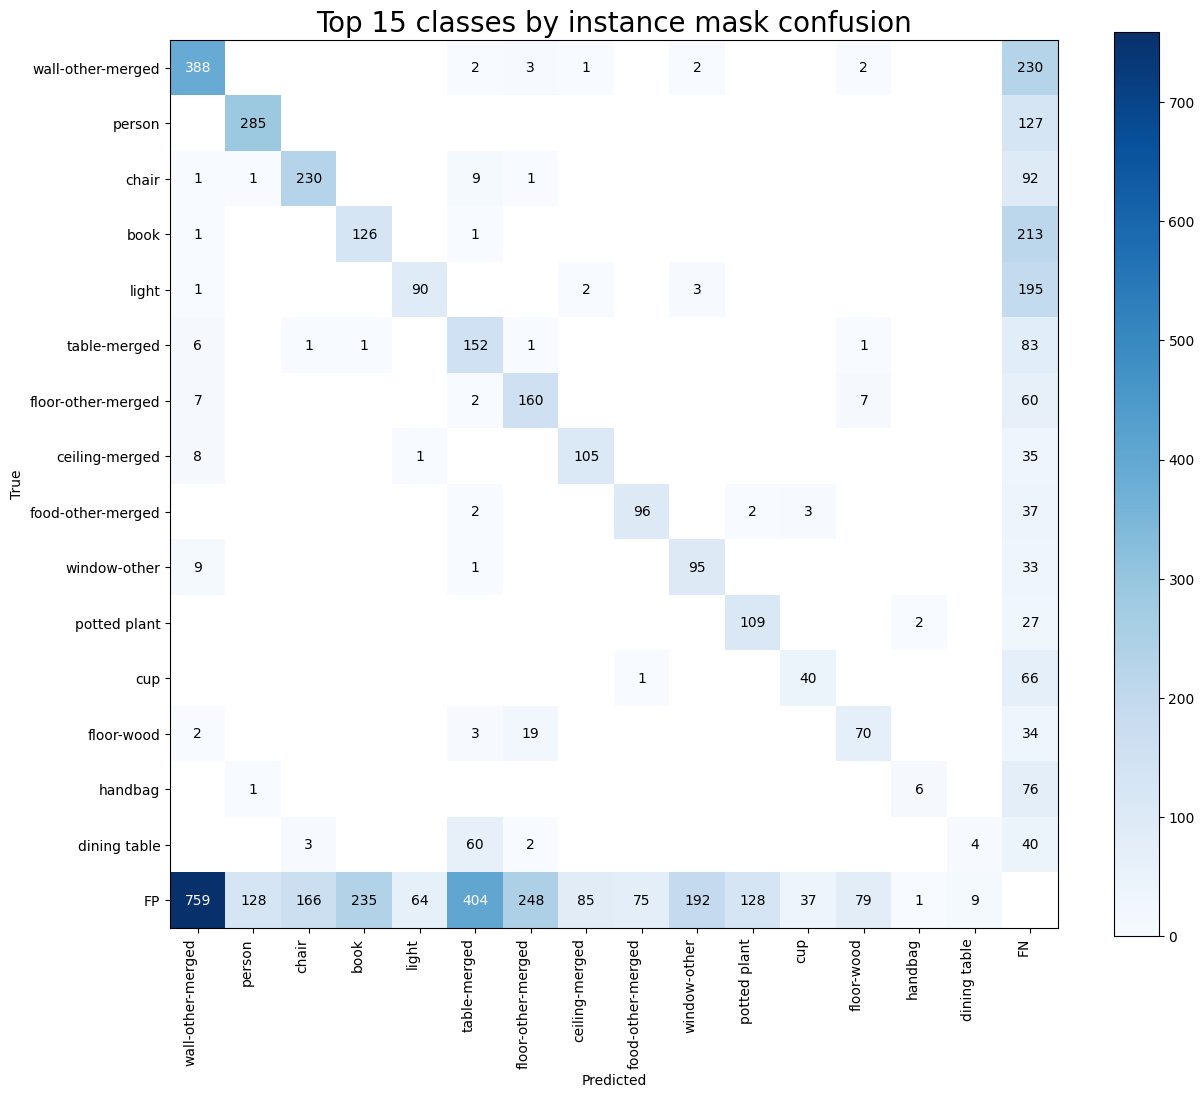

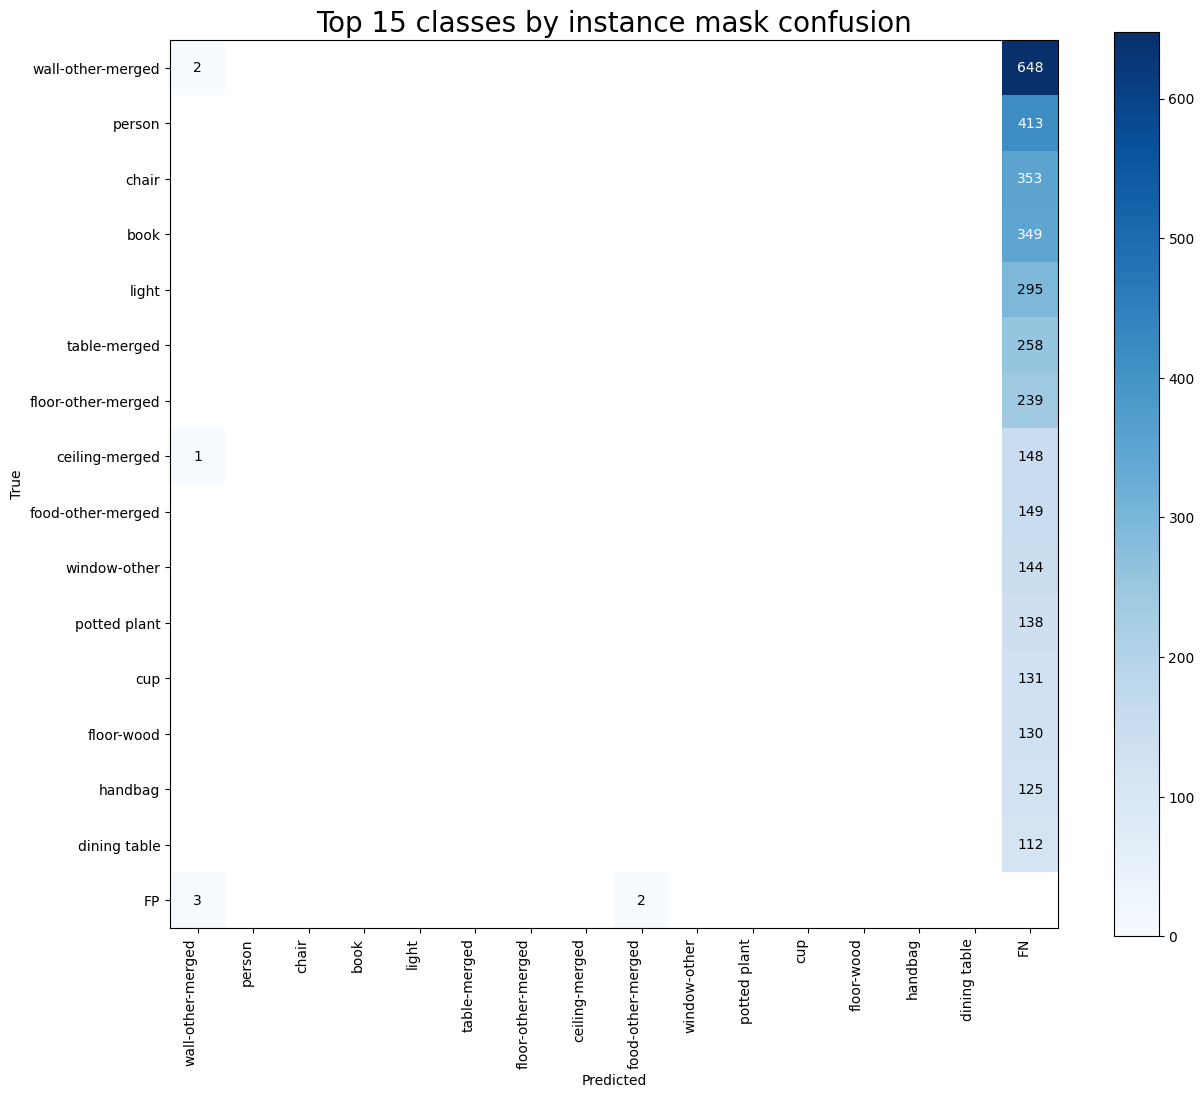

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import supervision as sv
from pycocotools.coco import COCO
from supervision.metrics import MetricTarget
from PIL import Image
from rfdetr import ClassThresholds


def save_rfdetr_confusion(matrix, output_dir):
    labels = CLASS_NAMES + ["background"]
    with (output_dir / "confusion_matrix.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["ground_truth / prediction", *labels])
        for label, row in zip(labels, matrix):
            writer.writerow([label, *row.tolist()])

    top_classes = sorted(range(len(CLASS_NAMES)), key=lambda index: matrix[index].sum(), reverse=True)[:15]
    visible_order = top_classes + [BACKGROUND_INDEX]
    display_matrix = sv.ConfusionMatrix(
        matrix=matrix[np.ix_(visible_order, visible_order)].astype(np.int32),
        classes=[CLASS_NAMES[index] for index in top_classes],
        conf_threshold=0.25,
        iou_threshold=0.5,
        metric_target=MetricTarget.MASKS,
    )
    display_matrix.plot(
        save_path=str(output_dir / "confusion_matrix_top15.png"),
        title="Top 15 classes by instance mask confusion",
        fig_size=(13, 11),
    )


def save_ground_truth_overlay(image, masks, labels, output_path):
    overlay = image.copy()
    colors = plt.get_cmap("tab20")
    for mask, class_index in zip(masks, labels):
        color = (np.asarray(colors(int(class_index) % 20)[:3]) * 255).astype(np.uint8)
        mask = np.asarray(mask, dtype=bool)
        overlay[mask] = (0.45 * overlay[mask] + 0.55 * color).astype(np.uint8)
    Image.fromarray(overlay).save(output_path)


def save_rfdetr_predictions(model, split_dir, output_dir, max_images=12):
    annotation_file = split_dir / "_annotations.coco.json"
    annotation_data = json.loads(annotation_file.read_text())
    coco = COCO(str(annotation_file))
    category_name_by_id = {item["id"]: item["name"] for item in annotation_data["categories"]}
    class_index_by_name = {name: index for index, name in enumerate(CLASS_NAMES)}
    foreground_threshold = ClassThresholds({}, default=0.25)
    confusion = np.zeros((len(CLASS_NAMES) + 1, len(CLASS_NAMES) + 1), dtype=np.int64)
    output_dir.mkdir(parents=True, exist_ok=True)
    input_dir = output_dir / "sample_inputs"
    ground_truth_dir = output_dir / "sample_ground_truth"
    prediction_dir = output_dir / "sample_predictions"
    for directory in (input_dir, ground_truth_dir, prediction_dir):
        directory.mkdir(parents=True, exist_ok=True)
    failures = []

    for sample_index, image_info in enumerate(annotation_data["images"]):
        image_path = split_dir / image_info["file_name"]
        image = np.asarray(Image.open(image_path).convert("RGB"))
        detections = model.predict(str(image_path), threshold=foreground_threshold)

        annotations = [
            item for item in coco.loadAnns(coco.getAnnIds(imgIds=[image_info["id"]]))
            if not item.get("iscrowd", 0)
        ]
        ground_truth_masks = [coco.annToMask(item).astype(bool) for item in annotations]
        ground_truth_labels = [
            class_index_by_name[category_name_by_id[item["category_id"]]]
            for item in annotations
        ]
        if annotations:
            ground_truth_boxes = np.asarray(
                [[x, y, x + width, y + height] for x, y, width, height in (item["bbox"] for item in annotations)],
                dtype=np.float32,
            )
            ground_truth_detections = sv.Detections(
                xyxy=ground_truth_boxes,
                mask=np.asarray(ground_truth_masks),
                class_id=np.asarray(ground_truth_labels, dtype=int),
            )
        else:
            ground_truth_detections = sv.Detections.empty()

        prediction_detections = detections if len(detections) else sv.Detections.empty()
        image_confusion = sv.ConfusionMatrix.from_detections(
            predictions=[prediction_detections],
            targets=[ground_truth_detections],
            classes=CLASS_NAMES,
            conf_threshold=0.25,
            iou_threshold=0.5,
            metric_target=MetricTarget.MASKS,
        ).matrix
        confusion += image_confusion
        matched_classes = image_confusion[:-1, :-1]
        false_positives = int(image_confusion[-1, :-1].sum())
        false_negatives = int(image_confusion[:-1, -1].sum())
        class_mismatches = int(matched_classes.sum() - np.trace(matched_classes))
        failures.append({
            "image": image_info["file_name"],
            "false_positives": false_positives,
            "false_negatives": false_negatives,
            "class_mismatches": class_mismatches,
            "total_errors": false_positives + false_negatives + class_mismatches,
        })

        if sample_index < max_images:
            shutil.copy2(image_path, input_dir / image_path.name)
            save_ground_truth_overlay(
                image,
                ground_truth_masks,
                ground_truth_labels,
                ground_truth_dir / image_path.name,
            )
            labels = [
                f"{CLASS_NAMES[int(class_id)]} {score:.2f}"
                for class_id, score in zip(detections.class_id, detections.confidence)
            ]
            annotated = sv.MaskAnnotator().annotate(image.copy(), detections)
            annotated = sv.LabelAnnotator().annotate(annotated, detections, labels=labels)
            Image.fromarray(annotated).save(prediction_dir / image_path.name)

    save_rfdetr_confusion(confusion, output_dir)
    failures.sort(key=lambda row: row["total_errors"], reverse=True)
    with (output_dir / "failure_candidates.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(
            file,
            fieldnames=["image", "false_positives", "false_negatives", "class_mismatches", "total_errors"],
        )
        writer.writeheader()
        writer.writerows(failures)

    failure_dir = output_dir / "failure_examples"
    failure_inputs = failure_dir / "inputs"
    failure_ground_truth = failure_dir / "ground_truth"
    failure_predictions = failure_dir / "predictions"
    for directory in (failure_inputs, failure_ground_truth, failure_predictions):
        directory.mkdir(parents=True, exist_ok=True)
    image_info_by_name = {item["file_name"]: item for item in annotation_data["images"]}
    for failure in failures[:5]:
        image_info = image_info_by_name[failure["image"]]
        image_path = split_dir / image_info["file_name"]
        image = np.asarray(Image.open(image_path).convert("RGB"))
        detections = model.predict(str(image_path), threshold=foreground_threshold)
        annotations = [
            item for item in coco.loadAnns(coco.getAnnIds(imgIds=[image_info["id"]]))
            if not item.get("iscrowd", 0)
        ]
        ground_truth_masks = [coco.annToMask(item).astype(bool) for item in annotations]
        ground_truth_labels = [
            class_index_by_name[category_name_by_id[item["category_id"]]]
            for item in annotations
        ]
        labels = [
            f"{CLASS_NAMES[int(class_id)]} {score:.2f}"
            for class_id, score in zip(detections.class_id, detections.confidence)
        ]
        annotated = sv.MaskAnnotator().annotate(image.copy(), detections)
        annotated = sv.LabelAnnotator().annotate(annotated, detections, labels=labels)
        shutil.copy2(image_path, failure_inputs / image_path.name)
        save_ground_truth_overlay(
            image,
            ground_truth_masks,
            ground_truth_labels,
            failure_ground_truth / image_path.name,
        )
        Image.fromarray(annotated).save(failure_predictions / image_path.name)


CLASS_NAMES = [item["name"] for item in sorted(train_annotations["categories"], key=lambda item: item["id"]) if item["name"] != "indoor-objects"]
BACKGROUND_INDEX = len(CLASS_NAMES)

for weights, model in (("pretrained", pretrained_model), ("scratch", scratch_model)):
    save_rfdetr_predictions(
        model,
        test,
        ARTIFACT_DIR / "rfdetr" / weights / "original_test",
    )


def flatten_numeric_metrics(value, prefix=""):
    flattened = []
    if isinstance(value, dict):
        for key, item in value.items():
            flattened.extend(flatten_numeric_metrics(item, f"{prefix}.{key}" if prefix else str(key)))
    elif isinstance(value, (list, tuple)):
        for index, item in enumerate(value):
            flattened.extend(flatten_numeric_metrics(item, f"{prefix}[{index}]"))
    elif isinstance(value, (int, float, np.integer, np.floating)):
        flattened.append({"metric": prefix, "value": float(value)})
    return flattened


rfdetr_summary_rows = []
for weights, metrics in (("pretrained", pretrained_metrics), ("scratch", scratch_metrics)):
    rfdetr_summary_rows.extend(
        {"weights": weights, "split": "original_test", **row}
        for row in flatten_numeric_metrics(metrics)
    )
with (ARTIFACT_DIR / "rfdetr_metrics_summary.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=["weights", "split", "metric", "value"])
    writer.writeheader()
    writer.writerows(rfdetr_summary_rows)

for weights in ("pretrained", "scratch"):
    metrics_file = CHECKPOINT_DIR / weights / "metrics.csv"
    if not metrics_file.exists():
        continue
    with metrics_file.open(newline="", encoding="utf-8") as file:
        log_rows = list(csv.DictReader(file))
    if not log_rows:
        continue
    metric_names = [
        name for name in log_rows[0]
        if "loss" in name.lower() or "map" in name.lower()
    ]
    if not metric_names:
        continue
    figure, axis = plt.subplots(figsize=(10, 5))
    for metric_name in metric_names:
        points = []
        for row in log_rows:
            try:
                points.append(float(row[metric_name]))
            except (TypeError, ValueError):
                points.append(np.nan)
        axis.plot(range(1, len(points) + 1), points, label=metric_name)
    axis.set_xlabel("Epoch")
    axis.set_title(f"RF-DETR {weights} training metrics")
    axis.legend()
    axis.grid(True, alpha=0.25)
    figure.tight_layout()
    figure.savefig(ARTIFACT_DIR / f"rfdetr_{weights}_training_curves.png", dpi=180)
    plt.close(figure)
